# 🤖 Real vs. AI-Generated Face Detection

Can a deep learning model tell real human faces from AI-generated ones? This project builds and compares five approaches on a small, fixed dataset, from a simple MLP to a fine-tuned **MobileNetV3**, and ends with an interactive **"Human vs. Model" Gradio game**.

### Highlights
- **Best model:** fine-tuned MobileNetV3Small with **76.0% test accuracy** (CNN trained from scratch: 63.3%)
- **12-run fine-tuning study** over unfreeze depth × learning rate, including a **BatchNorm ablation** (BatchNorm frozen: 78.9% vs trainable: 66.7% validation accuracy)
- **Error analysis** with confusion matrices, per-class recall, and agreement between models
- **Interactive demo:** a Gradio game where a player competes against the model

## Notebook structure

| Part | Topic | What it covers |
|------|-------|----------------|
| **0** | 🗂️ Dataset setup | Download, resize, normalize, split |
| **1** | 🔍 Data exploration | Sample faces, average faces, class balance |
| **2** | 🧠 MLP baseline | Fully connected network on flattened pixels |
| **3** | 🖼️ CNN baseline | Conv → BatchNorm → ReLU → Pool blocks with global average pooling |
| **4** | 🎨 Data augmentation | Subtle geometric augmentation with Keras preprocessing layers |
| **5** | 🚀 Transfer learning | Frozen MobileNetV3Small with a classifier-head comparison |
| **6** | 🔧 Fine-tuning | Coarse-to-fine grid, BatchNorm ablation, weight inspection |
| **7** | 📊 Model comparison | Accuracy, confusion matrices, sample predictions, consensus analysis |
| **8** | 🎮 Interactive demo | Gradio "Human vs. Model" game |

## 📊 Dataset
- **Size:** ~1,500 RGB face images (128×128×3): 1,020 training / 180 validation / 300 test
- **Classes:** binary, real (1) vs. AI-generated (0), balanced
- **Folders:** `training_real/`, `training_AI/`, `test_real/`, `test_AI/`
- **Note:** the dataset is not redistributed in this repository. To run the notebook, set `FILE_ID` in Part 0 to the Google Drive ID of a copy of the dataset zip, or point the paths to a local copy.

## Setup: Import Required Libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam

print(f"TensorFlow version: {tf.__version__}")
print(f"Running on: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

TensorFlow version: 2.20.0
Running on: GPU


## 🗂️ Part 0: Dataset Setup & Preprocessing

- **📥 Download:** fetch the dataset zip and extract it
- **🖼️ Image processing:** resize every image to 128×128 RGB
- **📈 Normalization:** scale pixel values to [0, 1]
- **🔀 Splits:**
  - **Test set:** a separate, fixed set of 300 images (150 per class) used only for final evaluation
  - **Training / validation:** the remaining 1,200 images, split 85% / 15% with stratification (1,020 / 180)

The same loading code is used for every model so that all comparisons are fair.

In [2]:
# ============================================================
# Part 0 - Dataset Setup
# ============================================================

!pip install -q gdown

import gdown
import os
import zipfile
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# Dataset zip hosted on Google Drive (not redistributed in this repository).
# Set FILE_ID to the Drive file ID of your copy of the dataset.
FILE_ID = "<YOUR_DATASET_FILE_ID>"
url = f"https://drive.google.com/uc?id={FILE_ID}"

print("📥 Downloading dataset...")
output_path = '/content/real_and_AI.zip'

try:
    gdown.download(url, output_path, quiet=False)

    print("\n📦 Extracting files...")
    with zipfile.ZipFile(output_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')

    # Clean up zip file
    os.remove(output_path)

    # Verify the download
    real_count = len(os.listdir('/content/real_and_AI/training_real'))
    fake_count = len(os.listdir('/content/real_and_AI/training_AI'))

    print("\n✅ Dataset successfully loaded!")
    print(f"   • Real faces: {real_count} images")
    print(f"   • AI faces: {fake_count} images")

except Exception as e:
    print(f"❌ Error downloading dataset: {e}")
    print("Check that FILE_ID points to a copy of the dataset.")




📥 Downloading dataset from course repository...


Downloading...
To: /content/real_and_AI.zip
100%|██████████| 66.9M/66.9M [00:00<00:00, 147MB/s]



📦 Extracting files...

✅ Dataset successfully loaded!
   • Real faces: 1001 images
   • AI faces: 1001 images


In [3]:
# ============================================================
# Load images into arrays
# ============================================================
print("\n" + "="*50)
print("Loading images into arrays...")

def load_images_from_folder(folder_path, label, max_images=600, target_size=(128, 128)):
    """
    Load images from a folder and assign a label.
    Images are loaded as RGB (3 channels) and normalized to [0, 1].
    """
    images, labels = [], []

    # Filter out hidden files (e.g. .DS_Store) and non-image files
    valid_extensions = ('.jpg', '.jpeg')
    image_files = [
        f for f in sorted(os.listdir(folder_path))
        if not f.startswith('.') and f.lower().endswith(valid_extensions)
    ][:max_images]

    for img_file in image_files:
        img_path = os.path.join(folder_path, img_file)
        try:
            img = Image.open(img_path)
            img = img.resize(target_size)
            img_array = np.array(img) / 255.0  # Normalize [0, 1]
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"⚠️ Error loading {img_file}: {e}")

    return np.array(images), np.array(labels)

# Paths
data_path = '/content/real_and_AI/'

# Training images
print("Loading real training images...")
real_images, real_labels = load_images_from_folder(
    os.path.join(data_path, 'training_real'),
    label=1
)
print("Loading AI-generated training images...")
fake_images, fake_labels = load_images_from_folder(
    os.path.join(data_path, 'training_AI'),
    label=0
)

# Combine training
X = np.concatenate([real_images, fake_images])
y = np.concatenate([real_labels, fake_labels])

# Test images (new fixed folders)
print("Loading real test images...")
test_real_images, test_real_labels = load_images_from_folder(
    os.path.join(data_path, 'test_real'),
    label=1
)
print("Loading fake test images...")
test_fake_images, test_fake_labels = load_images_from_folder(
    os.path.join(data_path, 'test_AI'),
    label=0
)

X_test = np.concatenate([test_real_images, test_fake_images])
y_test = np.concatenate([test_real_labels, test_fake_labels])

# Reshape
X = X.reshape(X.shape[0], 128, 128, 3)
X_test = X_test.reshape(X_test.shape[0], 128, 128, 3)

# Split training further into train/val (70/15/15 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

print(f"\n✅ Dataset ready for training!")
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Image shape: {X_train[0].shape}")
print(f"Real images: {np.sum(y == 1)} | Fake images: {np.sum(y == 0)}")


Loading images into arrays...
Loading real training images...
Loading AI-generated training images...
Loading real test images...
Loading fake test images...

✅ Dataset ready for training!
Train: 1020 | Val: 180 | Test: 300
Image shape: (128, 128, 3)
Real images: 600 | Fake images: 600


## 🔍 Part 1: Data Exploration & Visualization

Before building models, a quick look at what the data contains:
- **📐 Shapes** of the training, validation and test sets
- **🖼️ Sample faces** from both classes, side by side
- **👤 Average faces:** the pixel-wise mean real face vs. the mean AI face, to spot systematic differences (brightness, colour, face position) that a model might exploit as shortcuts
- **📈 Class balance** across all splits

Shapes:
 X_train: (1020, 128, 128, 3)  y_train: (1020,)
 X_val:   (180, 128, 128, 3)  y_val:   (180,)
 X_test:  (300, 128, 128, 3)  y_test:  (300,)



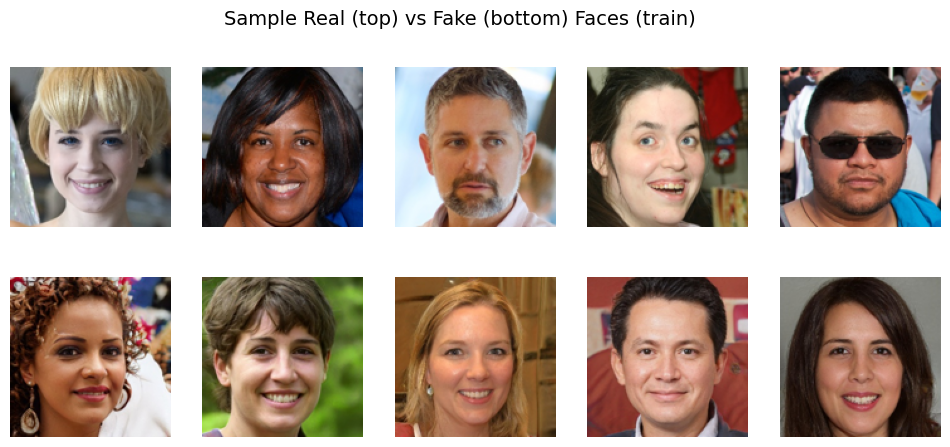

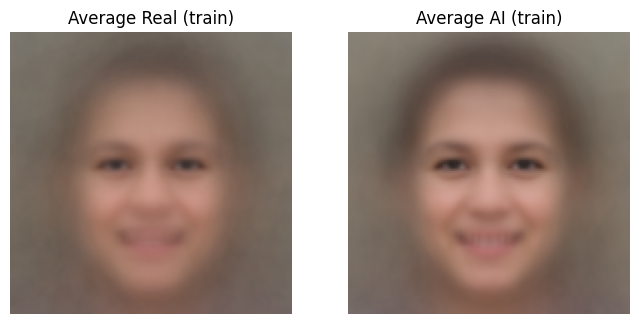

📊 Dataset statistics:
 Train  - Real: 510  AI: 510
 Val    - Real: 90  AI: 90
 Test   - Real: 150  AI: 150


In [4]:
# ============================================================
# Part 1 - Data Exploration
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Quick sanity checks
print("Shapes:")
print(" X_train:", X_train.shape, " y_train:", y_train.shape)
print(" X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print(" X_test: ", X_test.shape, " y_test: ", y_test.shape)
print()

# Show sample real vs fake images from training set
def pick_n_per_class(X, y, n=5, cls=1):
    idxs = np.where(y == cls)[0]
    sel = np.random.choice(idxs, size=min(n, len(idxs)), replace=False)
    return X[sel]

np.random.seed(42)
real_samples = pick_n_per_class(X_test, y_test, n=5, cls=1)
fake_samples = pick_n_per_class(X_test, y_test, n=5, cls=0)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample Real (top) vs Fake (bottom) Faces (train)", fontsize=14)

for i in range(5):
    axes[0, i].imshow(real_samples[i].reshape(128, 128, 3))
    axes[0, i].axis("off")
    axes[1, i].imshow(fake_samples[i].reshape(128, 128, 3))
    axes[1, i].axis("off")
plt.show()

# Compute average faces (train)
avg_real = X_train[y_train == 1].mean(axis=0)
avg_fake = X_train[y_train == 0].mean(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(avg_real.reshape(128, 128, 3)); ax1.set_title("Average Real (train)"); ax1.axis("off")
ax2.imshow(avg_fake.reshape(128, 128, 3)); ax2.set_title("Average AI (train)"); ax2.axis("off")
plt.show()

# Basic stats
print("📊 Dataset statistics:")
print(" Train  - Real:", np.sum(y_train==1), " AI:", np.sum(y_train==0))
print(" Val    - Real:", np.sum(y_val==1),   " AI:", np.sum(y_val==0))
print(" Test   - Real:", np.sum(y_test==1),  " AI:", np.sum(y_test==0))


## 🧠 Part 2: Multi-Layer Perceptron (MLP) Baseline

A fully connected network as the simplest baseline.

- **Architecture:** Flatten (128×128×3 = 49,152 inputs) → Dense 128 (ReLU) → Dense 64 (ReLU) → Dense 1 (sigmoid)
- **Training:** Adam (lr = 0.001), binary cross-entropy, 20 epochs, batch size 32
- **Parameters:** about 6.3M, almost all in the first layer

An MLP treats an image as a flat vector, so it has no notion of which pixels are neighbours. This baseline shows how much the spatial structure used by CNNs matters.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,299,905 (24.03 MB)

 Trainable params: 6,299,905 (24.03 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 127ms/step - accuracy: 0.5049 - loss: 2.5953 - val_accuracy: 0.5111 - val_loss: 1.6706
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5333 - loss: 1.1695 - val_accuracy: 0.5167 - val_loss: 1.2158
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5529 - loss: 1.0611 - val_accuracy: 0.6556 - val_loss: 0.6330
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.6255 - loss: 0.7742 - val_accuracy: 0.5222 - val_loss: 1.0644
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6039 - loss: 0.8232 - val_accuracy: 0.5889 - val_loss: 0.7464
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6284 - loss: 0.7761 - val_accuracy: 0.6389 - val_loss: 0.6438
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6559 - loss: 0.6823 - val_accuracy: 0.6333 - val_loss: 0.6821
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6873 - loss: 0.6089 - val_accuracy: 0.6056

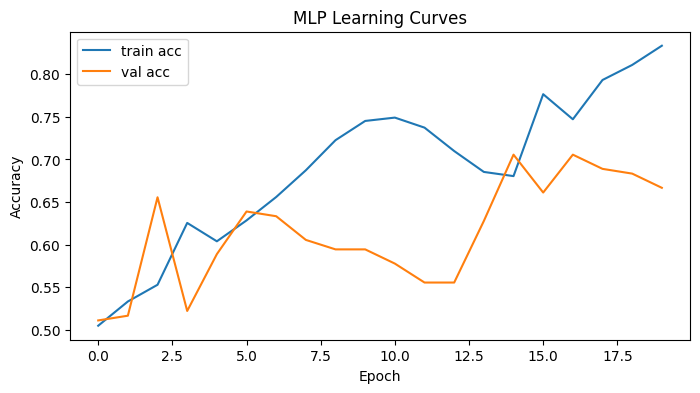

MLP test accuracy: 0.6433


In [5]:
# ============================================================
# Part 2 - Multi-Layer Perceptron
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Input # Import Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np

tf.random.set_seed(42)

mlp_model = Sequential([
    Input(shape=(128, 128, 3)),  # Use Input layer for input shape
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(mlp_model.summary())

history_mlp = mlp_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

# Best validation accuracy and epoch
best_val_acc_mlp = np.max(history_mlp.history['val_accuracy'])
best_epoch_mlp = np.argmax(history_mlp.history['val_accuracy']) + 1
print(f"MLP best val acc: {best_val_acc_mlp:.4f} at epoch {best_epoch_mlp}")

# Plot learning curves
plt.figure(figsize=(8,4))
plt.plot(history_mlp.history['accuracy'], label='train acc')
plt.plot(history_mlp.history['val_accuracy'], label='val acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("MLP Learning Curves")
plt.show()

# Evaluate on test set
mlp_test_loss, mlp_test_acc = mlp_model.evaluate(X_test, y_test, verbose=0)
print(f"MLP test accuracy: {mlp_test_acc:.4f}")

## 🖼️ Part 3: Convolutional Neural Network (CNN) Baseline

CNNs use the spatial structure of images: small filters slide across the image, so the same edge or texture detector works everywhere.

- **Blocks:** Conv2D → BatchNormalization → ReLU → MaxPooling (2×2) → Dropout, with filters increasing 16 → 32 → 64 as resolution decreases
- **Head:** GlobalAveragePooling2D → Dense 96 → BatchNorm → ReLU → Dropout → Dense 1 (sigmoid)
- **Why GlobalAveragePooling instead of Flatten:** far fewer parameters and less overfitting (about 31k parameters in total, ~200× fewer than the MLP)
- **Checkpointing:** the best model is saved based on validation loss (Part 4 revisits this choice)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │         6,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            97 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,641 (119.69 KB)

 Trainable params: 30,225 (118.07 KB)

 Non-trainable params: 416 (1.62 KB)

Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.4910 - loss: 0.7921
Epoch 1: val_loss improved from None to 0.69321, saving model to best_cnn_baseline.keras

Epoch 1: finished saving model to best_cnn_baseline.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 21s 306ms/step - accuracy: 0.4941 - loss: 0.7734 - val_accuracy: 0.5056 - val_loss: 0.6932
Epoch 2/25
29/32 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5335 - loss: 0.7311
Epoch 2: val_loss did not improve from 0.69321
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5402 - loss: 0.7266 - val_accuracy: 0.5000 - val_loss: 0.6970
Epoch 3/25
29/32 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5602 - loss: 0.6983
Epoch 3: val_loss did not improve from 0.69321
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5373 - loss: 0.7126 - val_accuracy: 0.5000 - val_loss: 0.7066
Epoch 4/25
29/32 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6018 - loss: 0.6585
Epoch 4: val_loss did not improve from 0.69321
32/32 ━━━━━━━━━━━━━━

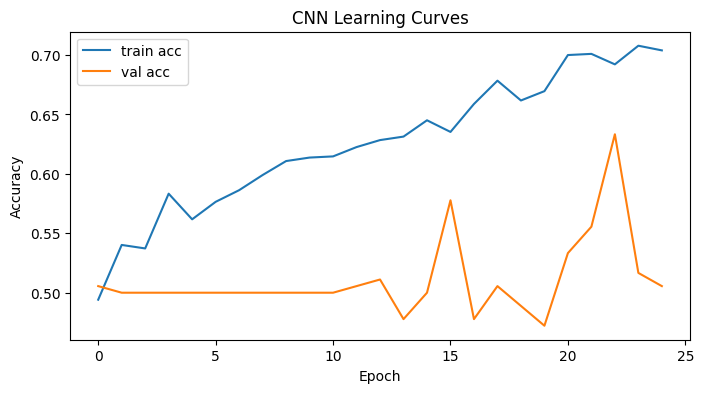

In [6]:

# ============================================================
# Part 3 - CNN (Baseline)
# ============================================================

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Activation, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt

# ---- CNN baseline ----

cnn_model = Sequential([
    # First conv block
    Conv2D(16, (3,3), padding='same', use_bias=False, input_shape=(128,128,3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Second conv block
    Conv2D(32, (3,3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Third conv block
    Conv2D(64, (3,3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    GlobalAveragePooling2D(),

    Dense(96),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.25),  # ← Increased final dropout

    Dense(1, activation='sigmoid')
])

cnn_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
cnn_model.summary()

checkpoint_cnn_path = "best_cnn_baseline.keras"
checkpoint_cnn = ModelCheckpoint(checkpoint_cnn_path, monitor='val_loss', save_best_only=True, mode='min', verbose=1)

history_cnn = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[checkpoint_cnn],
    verbose=1
)

best_val_acc_cnn = np.max(history_cnn.history['val_accuracy'])
best_val_loss_cnn = np.min(history_cnn.history['val_loss'])
best_epoch_cnn = np.argmin(history_cnn.history['val_loss']) + 1
print(f">> CNN baseline best val acc: {best_val_acc_cnn:.4f} at epoch {best_epoch_cnn}")

# Load best baseline cnn and evaluate on test set
best_cnn = load_model(checkpoint_cnn_path)
cnn_test_loss, cnn_test_acc = best_cnn.evaluate(X_test, y_test, verbose=0)
print(f">> CNN baseline test acc (best model): {cnn_test_acc:.4f}")

# Plot learning curves
plt.figure(figsize=(8,4))
plt.plot(history_cnn.history['accuracy'], label='train acc')
plt.plot(history_cnn.history['val_accuracy'], label='val acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("CNN Learning Curves")
plt.show()



## 🎨 Part 4: CNN with Data Augmentation

**Goal:** reduce overfitting on a small dataset by training on realistic variations of the images.

**Approach**
- Keras augmentation layers placed inside the model: they are only active during training, so validation, test and demo images are untouched
- Only subtle geometric transforms: horizontal flip, rotation ±11°, translation 5%, zoom 10%
- No blur, noise or colour changes, since these could erase the fine artifacts that give AI-generated images away
- Same architecture, optimizer and learning rate as the CNN baseline, so only the effect of augmentation is measured; the epoch budget is raised to 80 with early stopping because augmented data takes longer to learn
- Checkpoints are selected by **validation accuracy**. Selecting by validation loss restored a model that was just guessing: its loss was 0.693 = −ln(0.5), because a model that answers "50/50" for every face never makes a confident mistake

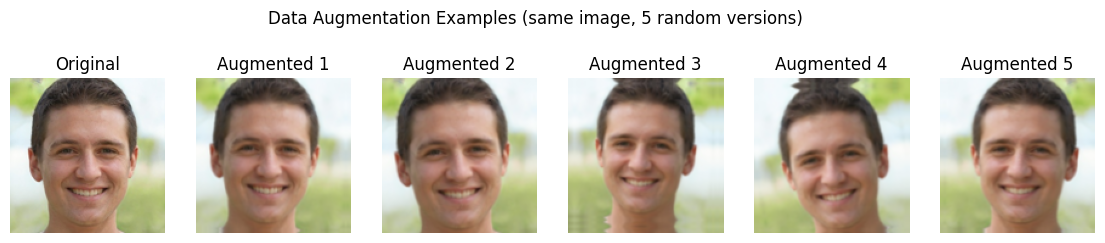

In [7]:
# ============================================================
# CNN with Data Augmentation
# ============================================================


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, BatchNormalization,
                                     Activation, Dropout, GlobalAveragePooling2D, Dense)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

tf.random.set_seed(42)

# Augmentation pipeline
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),                            # mirror left-right
    layers.RandomRotation(0.03, fill_mode="reflect"),           # 0.03 * 360° ≈ ±11°
    layers.RandomTranslation(0.05, 0.05, fill_mode="reflect"),  # shift up to 5%
    layers.RandomZoom(0.10, fill_mode="reflect"),               # zoom in/out up to 10%
], name="data_augmentation")

# what do augmented faces look like?
sample = tf.convert_to_tensor(X_train[:1], dtype=tf.float32)

plt.figure(figsize=(14, 3))
plt.subplot(1, 6, 1)
plt.imshow(X_train[0]); plt.title("Original"); plt.axis("off")
for i in range(5):
    aug = data_augmentation(sample, training=True)   # training=True forces augmentation ON
    plt.subplot(1, 6, i + 2)
    plt.imshow(np.clip(aug[0].numpy(), 0, 1)); plt.title(f"Augmented {i+1}"); plt.axis("off")
plt.suptitle("Data Augmentation Examples (same image, 5 random versions)")
plt.show()



Model: "cnn_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 96)             │         6,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            97 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 30,641 (119.69 KB)

 Trainable params: 30,225 (118.07 KB)

 Non-trainable params: 416 (1.62 KB)

Epoch 1/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5117 - loss: 0.7686
Epoch 1: val_accuracy improved from None to 0.50000, saving model to best_cnn_aug.keras

Epoch 1: finished saving model to best_cnn_aug.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.5255 - loss: 0.7512 - val_accuracy: 0.5000 - val_loss: 0.6965
Epoch 2/80
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5434 - loss: 0.7164
Epoch 2: val_accuracy did not improve from 0.50000
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5431 - loss: 0.7238 - val_accuracy: 0.5000 - val_loss: 0.7097
Epoch 3/80
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5447 - loss: 0.7122
Epoch 3: val_accuracy did not improve from 0.50000
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5235 - loss: 0.7225 - val_accuracy: 0.5000 - val_loss: 0.7337
Epoch 4/80
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5959 - loss: 0.6859
Epoch 4: val_accuracy did not improve from 0.50000
32/32 ━━━━━━━━━━━

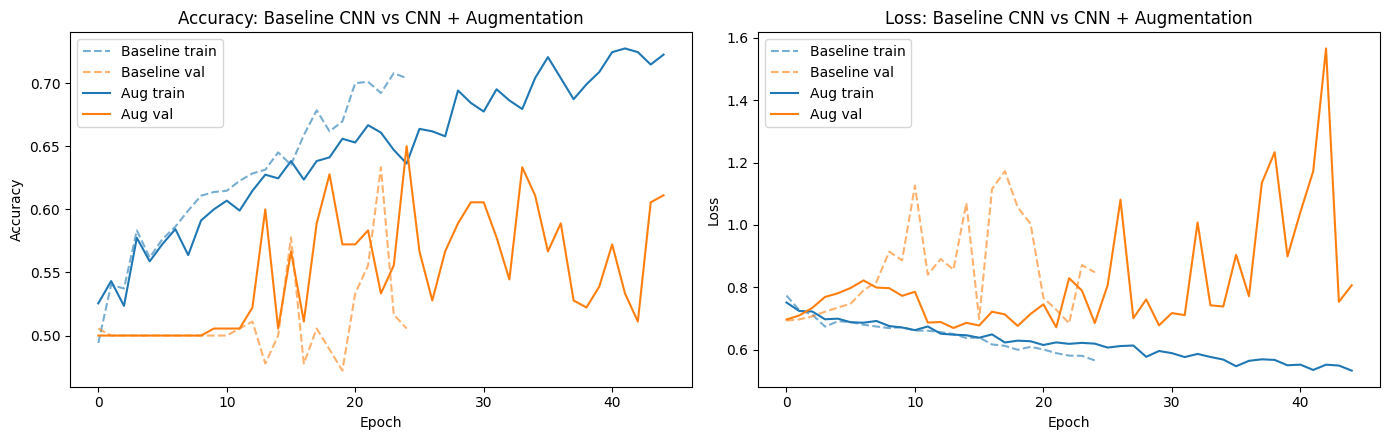


Model                   Test Acc     Train-Val Gap
-------------------------------------------------------
CNN Baseline              0.6333            0.0588
CNN + Augmentation        0.5633           -0.0137


In [8]:
# augmentation added at the front
tf.keras.utils.set_random_seed(42)   # reproducible weights, shuffling and augmentation
cnn_aug_model = Sequential([
    Input(shape=(128, 128, 3)),
    data_augmentation,

    # Block 1
    Conv2D(16, (3,3), padding='same', use_bias=False),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.15),

    # Block 2
    Conv2D(32, (3,3), padding='same', use_bias=False),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.15),

    # Block 3
    Conv2D(64, (3,3), padding='same', use_bias=False),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.15),

    GlobalAveragePooling2D(),
    Dense(96), BatchNormalization(), Activation('relu'), Dropout(0.25),
    Dense(1, activation='sigmoid')
], name="cnn_aug")

cnn_aug_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
cnn_aug_model.summary()

#  Callbacks
checkpoint_cnn_aug = ModelCheckpoint("best_cnn_aug.keras", monitor='val_accuracy',
                                     save_best_only=True, mode='max', verbose=1)
early_stop_aug = EarlyStopping(monitor='val_accuracy', mode='max', patience=20,
                               start_from_epoch=10,          # ignore the "know-nothing" early epochs
                               restore_best_weights=True, verbose=1)

# training
history_cnn_aug = cnn_aug_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=32,
    callbacks=[checkpoint_cnn_aug, early_stop_aug],
    verbose=1
)

# Report metrics
h = history_cnn_aug.history
best_epoch_aug = int(np.argmax(h['val_accuracy'])) + 1
val_acc_at_best_aug = h['val_accuracy'][best_epoch_aug - 1]
print(f">> CNN + Aug best epoch (max val_acc): {best_epoch_aug}")
print(f">> CNN + Aug val acc at that epoch:    {val_acc_at_best_aug:.4f}")

# Evaluating best checkpoint on test set
best_cnn_aug = load_model("best_cnn_aug.keras")
cnn_aug_test_loss, cnn_aug_test_acc = best_cnn_aug.evaluate(X_test, y_test, verbose=0)
print(f">> CNN+Aug test acc (best model):    {cnn_aug_test_acc:.4f}")

#Learning curves: baseline vs augmented
hb = history_cnn.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(hb['accuracy'], '--', color='tab:blue', alpha=0.6, label='Baseline train')
axes[0].plot(hb['val_accuracy'], '--', color='tab:orange', alpha=0.6, label='Baseline val')
axes[0].plot(h['accuracy'], color='tab:blue', label='Aug train')
axes[0].plot(h['val_accuracy'], color='tab:orange', label='Aug val')
axes[0].set_title("Accuracy: Baseline CNN vs CNN + Augmentation")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

axes[1].plot(hb['loss'], '--', color='tab:blue', alpha=0.6, label='Baseline train')
axes[1].plot(hb['val_loss'], '--', color='tab:orange', alpha=0.6, label='Baseline val')
axes[1].plot(h['loss'], color='tab:blue', label='Aug train')
axes[1].plot(h['val_loss'], color='tab:orange', label='Aug val')
axes[1].set_title("Loss: Baseline CNN vs CNN + Augmentation")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

plt.tight_layout()
plt.show()

# Comparison summary
gap_base = hb['accuracy'][best_epoch_cnn - 1] - hb['val_accuracy'][best_epoch_cnn - 1]
gap_aug  = h['accuracy'][best_epoch_aug - 1]  - h['val_accuracy'][best_epoch_aug - 1]

print("\n" + "="*55)
print(f"{'Model':<20}{'Test Acc':>12}{'Train-Val Gap':>18}")
print("-"*55)
print(f"{'CNN Baseline':<20}{cnn_test_acc:>12.4f}{gap_base:>18.4f}")
print(f"{'CNN + Augmentation':<20}{cnn_aug_test_acc:>12.4f}{gap_aug:>18.4f}")
print("="*55)

### 📌 Results: data augmentation
Augmentation kept the validation loss stable for much longer before overfitting, but test accuracy did not improve (56% vs 63%), and an earlier run showed the opposite. A plausible cause is that rotating and zooming slightly blur the image, which can hide the fine details the model needs.

**Takeaway:** augmentation delayed overfitting, but on its own it did not make the small CNN more accurate.

## 🚀 Part 5: Transfer Learning with MobileNetV3Small

**Approach**
- MobileNetV3Small pretrained on ImageNet (1.4M images), `include_top=False` with global average pooling, giving a 576-dimensional feature vector
- The backbone is fully frozen and called with `training=False`; only a new classifier head is trained (Adam, lr = 1e-3)
- Keras MobileNetV3 includes its own rescaling layer and expects pixels in **[0, 255]**, so the [0, 1] inputs are multiplied by 255 (feeding [0, 1] images silently degrades results)
- Augmentation is kept, and three classifier heads are compared and selected by validation accuracy (ties broken toward fewer parameters)
- The warning about adapting the input shape from 224×224 to 128×128 is expected for a fully convolutional backbone with global pooling

Reference: Howard et al., [*Searching for MobileNetV3*](https://openaccess.thecvf.com/content_ICCV_2019/html/Howard_Searching_for_MobileNetV3_ICCV_2019_paper.html), ICCV 2019.

In [9]:
# ============================================================
# Part 5 - Transfer Learning (MobileNetV3Small)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. Preprocessing
# arrays are in [0,1].
# (include_preprocessing=True) that expects raw [0,255] pixels, so just undid the /255.
X_train_pp = (X_train * 255.0).astype("float32")
X_val_pp   = (X_val   * 255.0).astype("float32")
X_test_pp  = (X_test  * 255.0).astype("float32")

print(f"Train: {X_train_pp.shape}  range [{X_train_pp.min():.1f}, {X_train_pp.max():.1f}]")
print(f"Val:   {X_val_pp.shape}  range [{X_val_pp.min():.1f}, {X_val_pp.max():.1f}]")
print(f"Test:  {X_test_pp.shape}  range [{X_test_pp.min():.1f}, {X_test_pp.max():.1f}]")


Train: (1020, 128, 128, 3)  range [0.0, 255.0]
Val:   (180, 128, 128, 3)  range [0.0, 255.0]
Test:  (300, 128, 128, 3)  range [0.0, 255.0]


In [10]:
# 2. New augmentation pipeline
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03, fill_mode="reflect"),
        layers.RandomTranslation(0.05, 0.05, fill_mode="reflect"),
        layers.RandomZoom(0.10, fill_mode="reflect"),
    ], name="data_augmentation")

# 3. Model builder: frozen MobileNetV3Small and a configurable head
def build_mobilenet_frozen(head="dense128"):
    base = MobileNetV3Small(
        input_shape=(128, 128, 3),
        include_top=False,          # drop ImageNet's 1000-class classifier
        weights="imagenet",
        pooling="avg",              # global average pooling - one feature vector per image
        include_preprocessing=True  # expects [0,255] input
    )
    base.trainable = False          # freeze all of the backbone weights

    inputs = keras.Input(shape=(128, 128, 3))
    x = make_augmentation()(inputs)
    x = base(x, training=False)

    if head == "linear":
        x = layers.Dropout(0.2)(x)
    elif head == "dense128":
        x = layers.Dense(128, activation="relu")(x)
        x = layers.Dropout(0.3)(x)
    elif head == "dense256_bn":
        x = layers.Dense(256, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=f"mobilenet_frozen_{head}")
    model.compile(optimizer=Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

# ---- 4. Head experiment: train each head, select by VALIDATION accuracy ----
heads = ["linear", "dense128", "dense256_bn"]
results = {}

for head in heads:
    print(f"\n{'='*60}\nTraining head: {head}\n{'='*60}")
    tf.keras.utils.set_random_seed(42)
    model = build_mobilenet_frozen(head)
    ckpt_path = f"best_mob_frozen_{head}.keras"

    hist = model.fit(
        X_train_pp, y_train,
        validation_data=(X_val_pp, y_val),
        epochs=30,
        batch_size=32,
        callbacks=[
            ModelCheckpoint(ckpt_path, monitor="val_accuracy", mode="max",
                            save_best_only=True, verbose=0),
            EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                          start_from_epoch=5, restore_best_weights=True, verbose=1),
        ],
        verbose=2   # one line per epoch
    )

    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    best_ep = int(np.argmax(hist.history["val_accuracy"])) + 1
    results[head] = {
        "history": hist,
        "ckpt": ckpt_path,
        "best_epoch": best_ep,
        "best_val_acc": float(np.max(hist.history["val_accuracy"])),
        "trainable": trainable,
        "total": model.count_params(),
    }

# 5. Head comparison table (validation only!)
print("\n" + "="*62)
print(f"{'Head':<14}{'Trainable':>12}{'Total':>12}{'Best Val Acc':>14}{'Epoch':>8}")
print("-"*62)
for head, r in results.items():
    print(f"{head:<14}{r['trainable']:>12,}{r['total']:>12,}{r['best_val_acc']:>14.4f}{r['best_epoch']:>8}")
print("="*62)

# Choosing the best head by val acc, then evaluating it once on test
best_head = max(results, key=lambda k: results[k]["best_val_acc"])
mobilenet_frozen   = load_model(results[best_head]["ckpt"])
history_mob_frozen = results[best_head]["history"]
mobilenet_frozen.save("best_mobilenet_frozen.keras")

mob_frozen_test_loss, mob_frozen_test_acc = mobilenet_frozen.evaluate(X_test_pp, y_test, verbose=0)
print(f"\n>> Selected head: {best_head}")
print(f">> MobileNetV3 (frozen) test accuracy: {mob_frozen_test_acc:.4f}")
mobilenet_frozen.summary()


Training head: linear


/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
32/32 - 10s - 313ms/step - accuracy: 0.5461 - loss: 0.7320 - val_accuracy: 0.5556 - val_loss: 0.7197
Epoch 2/30
32/32 - 1s - 43ms/step - accuracy: 0.5912 - loss: 0.6744 - val_accuracy: 0.6167 - val_loss: 0.6954
Epoch 3/30
32/32 - 1s - 36ms/step - accuracy: 0.6451 - loss: 0.6394 - val_accuracy: 0.6500 - val_loss: 0.6708
Epoch 4/30
32/32 - 1s - 36ms/step - accuracy: 0.6784 - loss: 0.6004 - val_accuracy: 0.6778 - val_loss: 0.6623
Epoch 5/30
32/32 - 1s - 20ms/step - accuracy: 0.6980 - loss: 0.5881 - val_accuracy: 0.6667 - val_loss: 0.6492
Epoch 6/30
32/32 - 1s - 25ms/step - accuracy: 0.6990 - loss: 0.5775 - val_accuracy: 0.6722 - val_loss: 0.6393
Epoch 7/30
32/32 - 1s - 35ms/step - accuracy: 0.7098 - loss: 0.5732 - val_accuracy: 0.6667 - val_loss: 0.6335
Epoch 8/30
32/32 - 1s - 21ms/step - accuracy: 0.7108 - loss: 0.5745 - val_accuracy: 0.6667 - val_loss: 0.6280
Epoch 9/30
32/32 - 1s - 22ms/step - accuracy: 0.7088 - loss: 0.5557 -

Model: "mobilenet_frozen_dense128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,161,077 (4.43 MB)

 Trainable params: 73,985 (289.00 KB)

 Non-trainable params: 939,120 (3.58 MB)

 Optimizer params: 147,972 (578.02 KB)

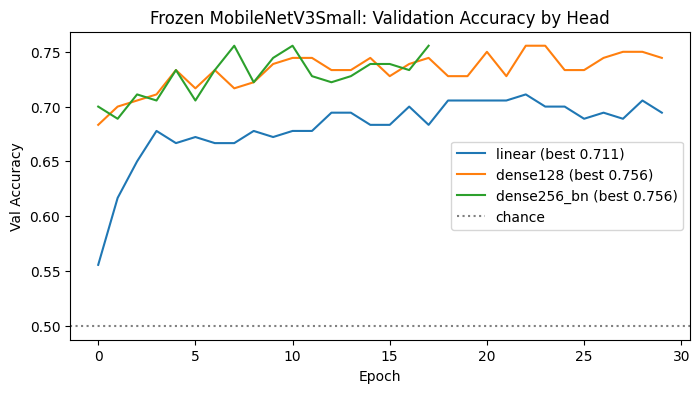

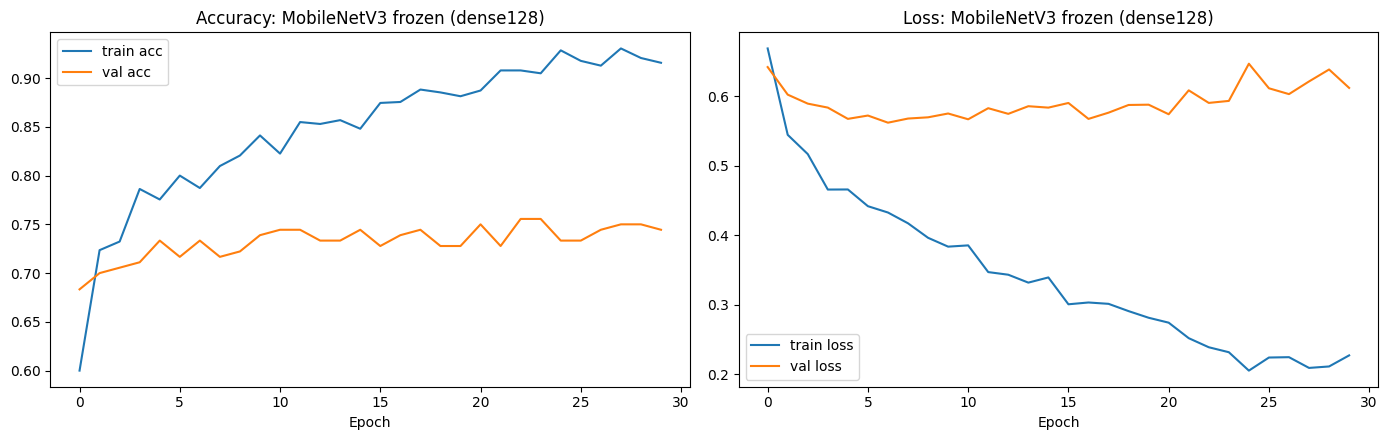

In [11]:
# Validation accuracy of all three heads
plt.figure(figsize=(8, 4))
for head, r in results.items():
    plt.plot(r["history"].history["val_accuracy"], label=f"{head} (best {r['best_val_acc']:.3f})")
plt.axhline(0.5, color="gray", linestyle=":", label="chance")
plt.title("Frozen MobileNetV3Small: Validation Accuracy by Head")
plt.xlabel("Epoch"); plt.ylabel("Val Accuracy"); plt.legend(); plt.show()

# Learning curves of the selected model
h = history_mob_frozen.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(h["accuracy"], label="train acc"); axes[0].plot(h["val_accuracy"], label="val acc")
axes[0].set_title(f"Accuracy: MobileNetV3 frozen ({best_head})")
axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train loss"); axes[1].plot(h["val_loss"], label="val loss")
axes[1].set_title(f"Loss: MobileNetV3 frozen ({best_head})")
axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

### 📌 Results: transfer learning

| Head | Trainable params | Best val acc |
|---|---|---|
| Linear | 577 | 0.711 |
| **Dense 128 + dropout (selected)** | 73,985 | **0.756** |
| Dense 256 + BatchNorm + dropout | 148,225 | 0.756 |

Test accuracy jumped to **71%**, and the model learned almost immediately. A hidden layer helped, but a bigger one did not, and validation accuracy stayed around 75% whatever head was used. This suggests the frozen ImageNet features themselves were the limit.

**Takeaway:** pretrained features beat everything trained from scratch, but they were never designed to spot AI artifacts.

## 🔧 Part 6: Fine-tuning MobileNetV3Small

Starting from the trained Part 5 model, the top of the backbone is unfrozen so its features can adapt to this task.

**Safeguards for a small dataset:** two-stage training (head first, then fine-tuning), early layers kept frozen, all BatchNorm layers kept frozen, small learning rates, ReduceLROnPlateau, and early stopping on validation accuracy.

**Experiments (coarse-to-fine)**
- **Round 1:** {15%, 30%, 50%} of layers unfrozen × learning rate {1e-5, 1e-4}, plus a deliberately naive setup (everything unfrozen, lr 1e-3, BatchNorm trainable)
- **Round 2:** refinement around the best region (70%, 100%, 3e-5, 3e-4) and a **BatchNorm ablation**: the naive setup with only BatchNorm frozen
- **Weight inspection:** checking whether BatchNorm statistics drifted during the naive run

**Questions explored:** which update sizes protect pretrained weights, why late blocks adapt better than early ones, and when fine-tuning can do worse than a frozen model.

In [12]:
# ============================================================
# Part 6 - Transfer Learning (MobileNetV3Small) + Fine-tuning
# ============================================================


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


frozen_ref = load_model("best_mobilenet_frozen.keras")
base_ref = frozen_ref.get_layer("MobileNetV3Small")

n_layers = len(base_ref.layers)
n_bn = sum(isinstance(l, layers.BatchNormalization) for l in base_ref.layers)
n_params = base_ref.count_params()
print(f"MobileNetV3Small: {n_layers} layers | {n_bn} BatchNorm layers | {n_params:,} params")

# check if the reloaded frozen model should reproduce its Part 5 val accuracy
_, frozen_val_acc = frozen_ref.evaluate(X_val_pp, y_val, verbose=0)
print(f"Frozen model val acc (reference): {frozen_val_acc:.4f}")

# Show the last 40 layers so  where the unfreeze cut points land is visible.
print("\nLast 40 layers of the backbone:")
for i, l in enumerate(base_ref.layers[-40:], start=n_layers - 40):
    n_w = sum(np.prod(w.shape) for w in l.weights)
    print(f"  [{i:3d}] {l.name:<40} {type(l).__name__:<22} {n_w:>8,} params")

MobileNetV3Small: 158 layers | 34 BatchNorm layers | 939,120 params
Frozen model val acc (reference): 0.7556

Last 40 layers of the backbone:
  [118] expanded_conv_8_squeeze_excite_relu      ReLU                          0 params
  [119] expanded_conv_8_squeeze_excite_conv_1    Conv2D                   21,024 params
  [120] re_lu_25                                 ReLU                          0 params
  [121] expanded_conv_8_squeeze_excite_mul       Multiply                      0 params
  [122] expanded_conv_8_project                  Conv2D                   27,648 params
  [123] expanded_conv_8_project_bn               BatchNormalization          384 params
  [124] expanded_conv_9_expand                   Conv2D                   55,296 params
  [125] expanded_conv_9_expand_bn                BatchNormalization        2,304 params
  [126] activation_39                            Activation                    0 params
  [127] expanded_conv_9_depthwise                DepthwiseConv2D  

In [13]:
# 2. Prepare model for fine-tuning
def prepare_finetune(unfreeze_frac, lr, freeze_bn=True):
    tf.keras.utils.set_random_seed(42)
    model = load_model("best_mobilenet_frozen.keras")     # start from the TRAINED head
    base = model.get_layer("MobileNetV3Small")
    base.trainable = True                                   # unlock then re-freeze selectively

    fine_tune_at = int(len(base.layers) * (1 - unfreeze_frac))
    for i, layer in enumerate(base.layers):
        if i < fine_tune_at:
            layer.trainable = False                         # early layers: generic features, keep frozen
        elif freeze_bn and isinstance(layer, layers.BatchNormalization):
            layer.trainable = False                         # protect ImageNet BN statistics
        else:
            layer.trainable = True

    # re-compile after changing trainable flags
    model.compile(optimizer=Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])

    trainable_layers = sum(l.trainable for l in base.layers)
    trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return model, fine_tune_at, trainable_layers, trainable_params


experiments = [
    # name,               unfreeze_frac, lr,   freeze_bn
    ("top15_lr1e-5",      0.15,          1e-5, True),
    ("top15_lr1e-4",      0.15,          1e-4, True),
    ("top30_lr1e-5",      0.30,          1e-5, True),
    ("top30_lr1e-4",      0.30,          1e-4, True),
    ("top50_lr1e-5",      0.50,          1e-5, True),
    ("top50_lr1e-4",      0.50,          1e-4, True),
    ("naive_all_lr1e-3",  1.00,          1e-3, False),   # deliberate failure case
]

ft_results = {}

for name, frac, lr, freeze_bn in experiments:
    model, cut, t_layers, t_params = prepare_finetune(frac, lr, freeze_bn)
    print(f"\n{'='*70}\n{name}: unfreezing from layer {cut} "
          f"('{model.get_layer('MobileNetV3Small').layers[cut].name}') | "
          f"trainable base layers: {t_layers} | trainable params: {t_params:,}\n{'='*70}")

    ckpt_path = f"best_ft_{name}.keras"
    hist = model.fit(
        X_train_pp, y_train,
        validation_data=(X_val_pp, y_val),
        epochs=40,
        batch_size=32,
        callbacks=[
            ModelCheckpoint(ckpt_path, monitor="val_accuracy", mode="max",
                            save_best_only=True, verbose=0),
            EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                          start_from_epoch=5, restore_best_weights=True, verbose=1),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                              min_lr=1e-7, verbose=1),
        ],
        verbose=2
    )

    va = hist.history["val_accuracy"]
    ft_results[name] = {
        "history": hist, "ckpt": ckpt_path, "frac": frac, "lr": lr, "freeze_bn": freeze_bn,
        "cut": cut, "t_layers": t_layers, "t_params": t_params,
        "best_val_acc": float(np.max(va)), "best_epoch": int(np.argmax(va)) + 1,
    }

# 4. Results table
print("\n" + "="*92)
print(f"{'Run':<20}{'Unfrozen':>10}{'LR':>9}{'BN':>9}{'Train params':>15}"
      f"{'Best Val':>11}{'Epoch':>8}{'Δ vs frozen':>13}")
print("-"*92)
for name, r in ft_results.items():
    bn = "frozen" if r["freeze_bn"] else "train"
    delta = r["best_val_acc"] - frozen_val_acc
    print(f"{name:<20}{r['frac']*100:>9.0f}%{r['lr']:>9.0e}{bn:>9}{r['t_params']:>15,}"
          f"{r['best_val_acc']:>11.4f}{r['best_epoch']:>8}{delta:>+13.4f}")
print("="*92)

#  5. Select by val acc, tie-break on lesser trainable params
best_name = sorted(ft_results, key=lambda k: (-ft_results[k]["best_val_acc"], ft_results[k]["t_params"]))[0]
mobilenet_finetuned   = load_model(ft_results[best_name]["ckpt"])
history_mob_finetuned = ft_results[best_name]["history"]
mobilenet_finetuned.save("best_mobilenet_finetuned.keras")

#  6. Test evaluation: selected fine-tuned model vs frozen
mob_ft_test_loss, mob_ft_test_acc = mobilenet_finetuned.evaluate(X_test_pp, y_test, verbose=0)
print(f"\n>> Selected fine-tuning run: {best_name}")
print(f">> Frozen MobileNetV3 test acc:     {mob_frozen_test_acc:.4f}")
print(f">> Fine-tuned MobileNetV3 test acc: {mob_ft_test_acc:.4f}  "
      f"(Δ {mob_ft_test_acc - mob_frozen_test_acc:+.4f})")


top15_lr1e-5: unfreezing from layer 134 ('re_lu_26') | trainable base layers: 19 | trainable params: 476,177
Epoch 1/40
32/32 - 11s - 354ms/step - accuracy: 0.9284 - loss: 0.2139 - val_accuracy: 0.7611 - val_loss: 0.5874 - learning_rate: 1.0000e-05
Epoch 2/40
32/32 - 1s - 28ms/step - accuracy: 0.9137 - loss: 0.2197 - val_accuracy: 0.7556 - val_loss: 0.5879 - learning_rate: 1.0000e-05
Epoch 3/40
32/32 - 1s - 24ms/step - accuracy: 0.9284 - loss: 0.2034 - val_accuracy: 0.7611 - val_loss: 0.5867 - learning_rate: 1.0000e-05
Epoch 4/40
32/32 - 1s - 25ms/step - accuracy: 0.9176 - loss: 0.2152 - val_accuracy: 0.7611 - val_loss: 0.5850 - learning_rate: 1.0000e-05
Epoch 5/40
32/32 - 1s - 25ms/step - accuracy: 0.9314 - loss: 0.2018 - val_accuracy: 0.7556 - val_loss: 0.5845 - learning_rate: 1.0000e-05
Epoch 6/40
32/32 - 1s - 29ms/step - accuracy: 0.9206 - loss: 0.2071 - val_accuracy: 0.7611 - val_loss: 0.5845 - learning_rate: 1.0000e-05
Epoch 7/40
32/32 - 1s - 24ms/step - accuracy: 0.9412 - loss:

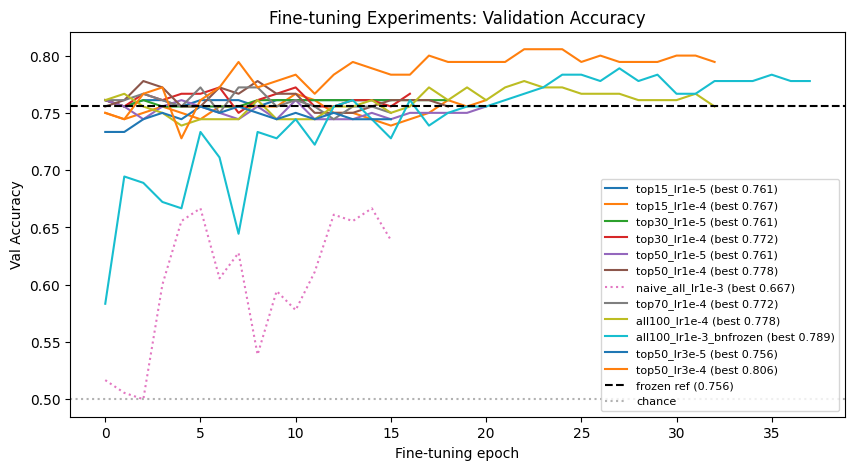

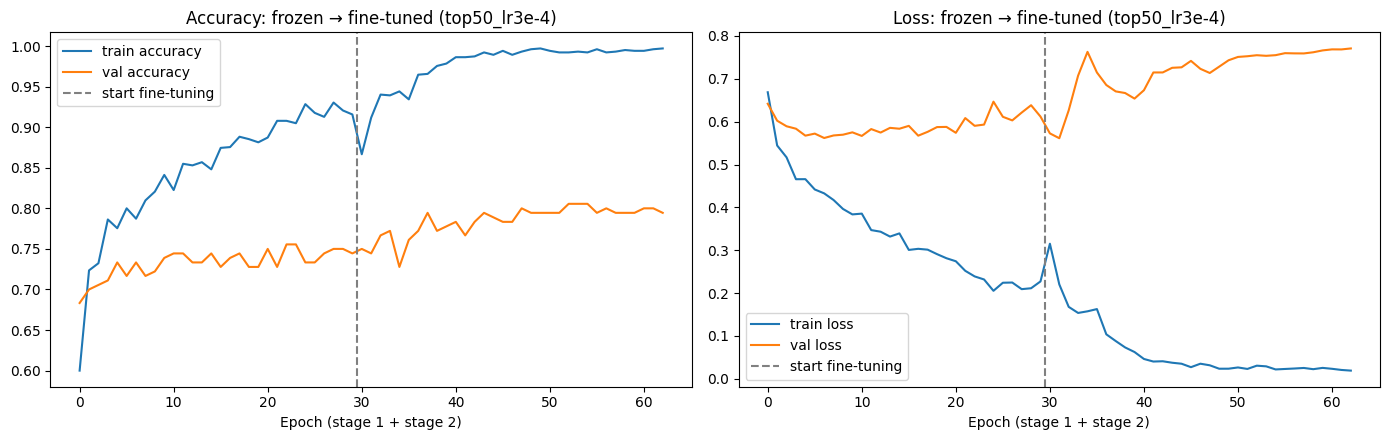

In [24]:
# 7a. Val accuracy of every fine-tuning run vs the frozen layer
plt.figure(figsize=(10, 5))
for name, r in ft_results.items():
    style = ":" if not r["freeze_bn"] else "-"
    plt.plot(r["history"].history["val_accuracy"], style, label=f"{name} (best {r['best_val_acc']:.3f})")
plt.axhline(frozen_val_acc, color="black", linestyle="--", label=f"frozen ref ({frozen_val_acc:.3f})")
plt.axhline(0.5, color="gray", linestyle=":", alpha=0.6, label="chance")
plt.title("Fine-tuning Experiments: Validation Accuracy")
plt.xlabel("Fine-tuning epoch"); plt.ylabel("Val Accuracy")
plt.legend(fontsize=8, loc="lower right"); plt.show()

# 7b. Full two-stage curve: frozen (Part 5) -> fine-tuned (Part 6)
hf, ht = history_mob_frozen.history, history_mob_finetuned.history
n_f = len(hf["accuracy"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(hf[metric] + ht[metric], label=f"train {metric}")
    ax.plot(hf[f"val_{metric}"] + ht[f"val_{metric}"], label=f"val {metric}")
    ax.axvline(n_f - 0.5, color="gray", linestyle="--", label="start fine-tuning")
    ax.set_title(f"{title}: frozen → fine-tuned ({best_name})")
    ax.set_xlabel("Epoch (stage 1 + stage 2)"); ax.legend()
plt.tight_layout(); plt.show()

In [15]:
# ============================================================
# Part 6 - Round 2: refine around the best region + BN ablation
# ============================================================
def run_ft_experiment(name, frac, lr, freeze_bn, epochs=40):
    model, cut, t_layers, t_params = prepare_finetune(frac, lr, freeze_bn)
    print(f"\n{'='*70}\n{name}: cut at layer {cut} | trainable base layers: {t_layers} "
          f"| trainable params: {t_params:,}\n{'='*70}")
    ckpt_path = f"best_ft_{name}.keras"
    hist = model.fit(
        X_train_pp, y_train,
        validation_data=(X_val_pp, y_val),
        epochs=epochs, batch_size=32,
        callbacks=[
            ModelCheckpoint(ckpt_path, monitor="val_accuracy", mode="max", save_best_only=True, verbose=0),
            EarlyStopping(monitor="val_accuracy", mode="max", patience=10,
                          start_from_epoch=5, restore_best_weights=True, verbose=1),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7, verbose=1),
        ],
        verbose=2
    )
    va = hist.history["val_accuracy"]
    ft_results[name] = {
        "history": hist, "ckpt": ckpt_path, "frac": frac, "lr": lr, "freeze_bn": freeze_bn,
        "cut": cut, "t_layers": t_layers, "t_params": t_params,
        "best_val_acc": float(np.max(va)), "best_epoch": int(np.argmax(va)) + 1,
    }

experiments_round2 = [
    # name,                     frac, lr,   freeze_bn
    ("top70_lr1e-4",            0.70, 1e-4, True),
    ("all100_lr1e-4",           1.00, 1e-4, True),
    ("all100_lr1e-3_bnfrozen",  1.00, 1e-3, True),   # ablation partner of naive_all_lr1e-3
    ("top50_lr3e-5",            0.50, 3e-5, True),
    ("top50_lr3e-4",            0.50, 3e-4, True),
]
for exp in experiments_round2:
    run_ft_experiment(*exp)

# ---- Full results table, sorted by val acc ----
print("\n" + "="*96)
print(f"{'Run':<24}{'Unfrozen':>10}{'LR':>9}{'BN':>9}{'Train params':>15}"
      f"{'Best Val':>11}{'Epoch':>8}{'Δ vs frozen':>13}")
print("-"*96)
for name in sorted(ft_results, key=lambda k: -ft_results[k]["best_val_acc"]):
    r = ft_results[name]
    bn = "frozen" if r["freeze_bn"] else "train"
    print(f"{name:<24}{r['frac']*100:>9.0f}%{r['lr']:>9.0e}{bn:>9}{r['t_params']:>15,}"
          f"{r['best_val_acc']:>11.4f}{r['best_epoch']:>8}{r['best_val_acc']-frozen_val_acc:>+13.4f}")
print("="*96)

# ---- BN ablation: same layers & LR, only BN setting differs ----
a, b = ft_results["naive_all_lr1e-3"], ft_results["all100_lr1e-3_bnfrozen"]
print(f"\nBN ablation (100% unfrozen, LR 1e-3):")
print(f"  BN trainable: best val {a['best_val_acc']:.4f}  |  first-epoch val {a['history'].history['val_accuracy'][0]:.4f}")
print(f"  BN frozen:    best val {b['best_val_acc']:.4f}  |  first-epoch val {b['history'].history['val_accuracy'][0]:.4f}")

# ---- Re-select across ALL runs (tie-break: fewer trainable params), test once ----
best_name = sorted(ft_results, key=lambda k: (-ft_results[k]["best_val_acc"], ft_results[k]["t_params"]))[0]
mobilenet_finetuned   = load_model(ft_results[best_name]["ckpt"])
history_mob_finetuned = ft_results[best_name]["history"]
mobilenet_finetuned.save("best_mobilenet_finetuned.keras")

mob_ft_test_loss, mob_ft_test_acc = mobilenet_finetuned.evaluate(X_test_pp, y_test, verbose=0)
print(f"\n>> Selected fine-tuning run (all rounds): {best_name}")
print(f">> Frozen MobileNetV3 test acc:     {mob_frozen_test_acc:.4f}")
print(f">> Fine-tuned MobileNetV3 test acc: {mob_ft_test_acc:.4f}  (Δ {mob_ft_test_acc - mob_frozen_test_acc:+.4f})")


top70_lr1e-4: cut at layer 47 | trainable base layers: 88 | trainable params: 969,793
Epoch 1/40
32/32 - 16s - 490ms/step - accuracy: 0.9059 - loss: 0.2324 - val_accuracy: 0.7611 - val_loss: 0.5869 - learning_rate: 1.0000e-04
Epoch 2/40
32/32 - 1s - 42ms/step - accuracy: 0.9216 - loss: 0.1940 - val_accuracy: 0.7611 - val_loss: 0.5680 - learning_rate: 1.0000e-04
Epoch 3/40
32/32 - 2s - 57ms/step - accuracy: 0.9451 - loss: 0.1578 - val_accuracy: 0.7667 - val_loss: 0.6345 - learning_rate: 1.0000e-04
Epoch 4/40
32/32 - 1s - 38ms/step - accuracy: 0.9441 - loss: 0.1550 - val_accuracy: 0.7611 - val_loss: 0.6465 - learning_rate: 1.0000e-04
Epoch 5/40
32/32 - 1s - 38ms/step - accuracy: 0.9539 - loss: 0.1299 - val_accuracy: 0.7556 - val_loss: 0.6173 - learning_rate: 1.0000e-04
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
32/32 - 2s - 68ms/step - accuracy: 0.9520 - loss: 0.1252 - val_accuracy: 0.7722 - val_loss: 0.6767 - learning_rate: 1.0000e-04
Epoch 

In [16]:
# ---- Did BN running statistics change in the naive run? ----
ref   = load_model("best_mobilenet_frozen.keras").get_layer("MobileNetV3Small")
naive = load_model("best_ft_naive_all_lr1e-3.keras").get_layer("MobileNetV3Small")

bn_ref = [l for l in ref.layers   if isinstance(l, layers.BatchNormalization)]
bn_nv  = [l for l in naive.layers if isinstance(l, layers.BatchNormalization)]

def mean_abs_diff(attr):
    return np.mean([np.abs(getattr(a, attr).numpy() - getattr(b, attr).numpy()).mean()
                    for a, b in zip(bn_ref, bn_nv)])

for attr in ["moving_mean", "moving_variance", "gamma", "beta"]:
    print(f"{attr:<16} avg |change|: {mean_abs_diff(attr):.6f}")

moving_mean      avg |change|: 0.038752
moving_variance  avg |change|: 3.529653
gamma            avg |change|: 0.008436
beta             avg |change|: 0.005825


### 📌 Results: fine-tuning

| Run | Unfrozen | Learning rate | BatchNorm | Best val acc |
|---|---|---|---|---|
| Frozen (Part 5 reference) | 0% | – | – | 0.756 |
| top15_lr1e-4 | 15% | 1e-4 | frozen | 0.767 |
| top30_lr1e-4 | 30% | 1e-4 | frozen | 0.772 |
| top50_lr1e-5 | 50% | 1e-5 | frozen | 0.761 |
| top50_lr1e-4 | 50% | 1e-4 | frozen | 0.778 |
| **top50_lr3e-4 (selected)** | 50% | 3e-4 | frozen | **0.806** |
| top70_lr1e-4 | 70% | 1e-4 | frozen | 0.772 |
| all100_lr1e-4 | 100% | 1e-4 | frozen | 0.778 |
| all100_lr1e-3 | 100% | 1e-3 | frozen | 0.789 |
| naive_all_lr1e-3 | 100% | 1e-3 | trainable | 0.667 |

- **Learning rate mattered most.** Too small (1e-5) changed nothing, 1e-4 to 3e-4 worked best, and 1e-3 disrupted the model at first.
- **Unfreezing more than about half the network did not help further.** The top layers are the ones that need to adapt; early layers detect general edges and textures that are useful for any image.
- **BatchNorm was the main reason the naive setup failed.** With everything unfrozen and BatchNorm trainable, the model did worse than no fine-tuning at all; the same setup with only BatchNorm frozen worked well. Checking the weights showed why: BatchNorm's stored ImageNet statistics had been overwritten by statistics from small batches of faces.
- **The selected model reached 76% test accuracy, the best overall.** It still overfits, and since it was chosen from 12 runs, the real gain over the frozen model is probably a few points.

**Takeaway:** fine-tuning helps, but only with a small learning rate and frozen BatchNorm.

## 📊 Part 7: Model Comparison & Analysis

All five models (MLP, CNN, CNN + augmentation, frozen MobileNet, fine-tuned MobileNet) are compared on the same test set, with every metric recomputed from the saved models:

1. **Performance comparison:** best validation accuracy vs. test accuracy for each model
2. **Confusion matrices:** a 2×3 grid with the five models plus a majority vote of all five
3. **Sample predictions:** test faces with every model's score (0.0 = AI, 1.0 = Real), highlighting disagreements
4. **Analysis:** performance ranking, train–validation gap, confusion patterns, faces that fool every model, and which model is right when they disagree

Model              Params   Train     Val  BestVal    Test     Gap  AI rec  Real rec   %Real
--------------------------------------------------------------------------------------------
MLP             6,299,905   0.868   0.667    0.706   0.643  +0.201   0.727     0.560   41.7%
CNN                30,641   0.661   0.633    0.633   0.633  +0.027   0.380     0.887   75.3%
CNN+Aug            30,641   0.647   0.650    0.650   0.563  -0.003   0.387     0.740   67.7%
MobileNet       1,013,105   0.930   0.756    0.756   0.713  +0.175   0.727     0.700   48.7%
MobileNet-FT    1,013,105   0.996   0.806    0.806   0.760  +0.191   0.753     0.767   50.7%
Majority vote           -       -       -        -   0.710       -   0.640     0.780   57.0%
Gap = clean train acc - val acc | AI rec = share of AI faces caught | %Real = share predicted Real (balanced = 50%)


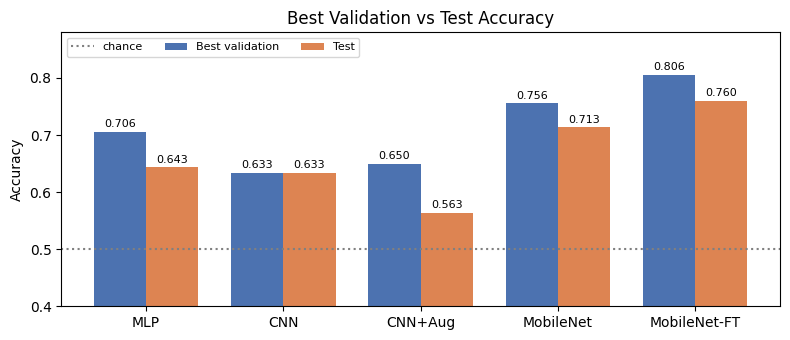

In [17]:
# ============================================================
# Part 7 - Model Comparison & Analysis
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import load_model

# Models + correct input type (MLP/CNNs: [0,1], MobileNets: [0,255])
registry = {
    "MLP":          (mlp_model,                                    "raw", history_mlp),
    "CNN":          (load_model("best_cnn_baseline.keras"),        "raw", history_cnn),
    "CNN+Aug":      (load_model("best_cnn_aug.keras"),             "raw", history_cnn_aug),
    "MobileNet":    (load_model("best_mobilenet_frozen.keras"),    "pp",  history_mob_frozen),
    "MobileNet-FT": (load_model("best_mobilenet_finetuned.keras"), "pp",  history_mob_finetuned),
}
data = {"raw": (X_train, X_val, X_test), "pp": (X_train_pp, X_val_pp, X_test_pp)}
names = list(registry)

# Fresh predictions (train acc on clean images in eval mode -> fair gap)
S = {}
for n, (m, kind, hist) in registry.items():
    Xtr, Xva, Xte = data[kind]
    p_te = m.predict(Xte, verbose=0).ravel()
    tr = np.mean((m.predict(Xtr, verbose=0).ravel() > 0.5) == y_train)
    va = np.mean((m.predict(Xva, verbose=0).ravel() > 0.5) == y_val)
    S[n] = dict(p=p_te, test=np.mean((p_te > 0.5) == y_test), train=tr, val=va,
                best_val=float(np.max(hist.history["val_accuracy"])), params=m.count_params())

P = np.stack([S[n]["p"] for n in names])          # (5, 300) sigmoid scores
preds = (P > 0.5).astype(int)
correct = preds == y_test
n_correct = correct.sum(axis=0)
majority = (preds.sum(axis=0) >= 3).astype(int)   # >= 3 of 5 models say Real

def class_stats(pr):
    tn, fp, fn, tp = confusion_matrix(y_test, pr, labels=[0, 1]).ravel()
    return tn / (tn + fp), tp / (tp + fn), pr.mean()   # AI recall, Real recall, % predicted Real

# Master table
hdr = f"{'Model':<14}{'Params':>11}{'Train':>8}{'Val':>8}{'BestVal':>9}{'Test':>8}{'Gap':>8}{'AI rec':>8}{'Real rec':>10}{'%Real':>8}"
print("="*len(hdr)); print(hdr); print("-"*len(hdr))
for i, n in enumerate(names):
    s = S[n]; ai, re, pr = class_stats(preds[i])
    print(f"{n:<14}{s['params']:>11,}{s['train']:>8.3f}{s['val']:>8.3f}{s['best_val']:>9.3f}"
          f"{s['test']:>8.3f}{s['train']-s['val']:>+8.3f}{ai:>8.3f}{re:>10.3f}{pr*100:>7.1f}%")
ai, re, pr = class_stats(majority)
print(f"{'Majority vote':<14}{'-':>11}{'-':>8}{'-':>8}{'-':>9}{np.mean(majority == y_test):>8.3f}"
      f"{'-':>8}{ai:>8.3f}{re:>10.3f}{pr*100:>7.1f}%")
print("="*len(hdr))
print("Gap = clean train acc - val acc | AI rec = share of AI faces caught | %Real = share predicted Real (balanced = 50%)")

# Grouped bar chart
x, w = np.arange(len(names)), 0.38
fig, ax = plt.subplots(figsize=(8, 3.5))
for off, key, lab, col in [(-w/2, "best_val", "Best validation", "#4C72B0"), (w/2, "test", "Test", "#DD8452")]:
    bars = ax.bar(x + off, [S[n][key] for n in names], w, label=lab, color=col)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.axhline(0.5, color="gray", linestyle=":", label="chance")
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0.4, 0.88)
ax.set_ylabel("Accuracy"); ax.set_title("Best Validation vs Test Accuracy")
ax.legend(fontsize=8, loc="upper left", ncol=3); plt.tight_layout()
plt.savefig("fig_p7_bars.png", dpi=200, bbox_inches="tight"); plt.show()

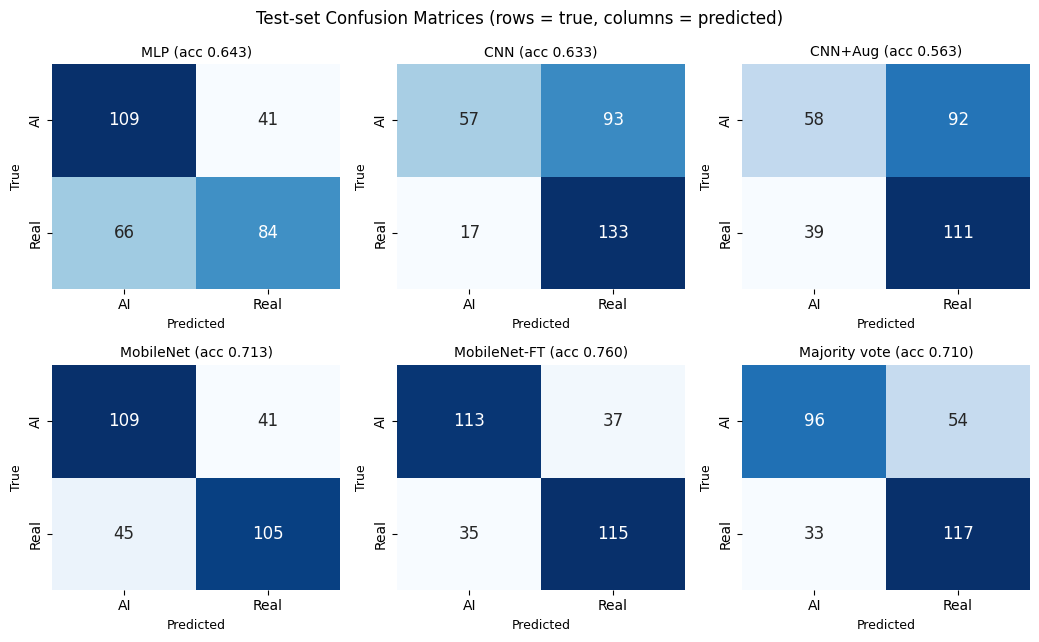

In [18]:
# 2x3 grid: 5 models + majority vote in the free 6th slot
panels = [(n, preds[i], S[n]["test"]) for i, n in enumerate(names)]
panels.append(("Majority vote", majority, np.mean(majority == y_test)))

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.5))
for ax, (title, pr, acc) in zip(axes.ravel(), panels):
    cm = confusion_matrix(y_test, pr, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["AI", "Real"], yticklabels=["AI", "Real"], annot_kws={"size": 12})
    ax.set_title(f"{title} (acc {acc:.3f})", fontsize=10)
    ax.set_xlabel("Predicted", fontsize=9); ax.set_ylabel("True", fontsize=9)
plt.suptitle("Test-set Confusion Matrices (rows = true, columns = predicted)", fontsize=12)
plt.tight_layout()
plt.savefig("fig_p7_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

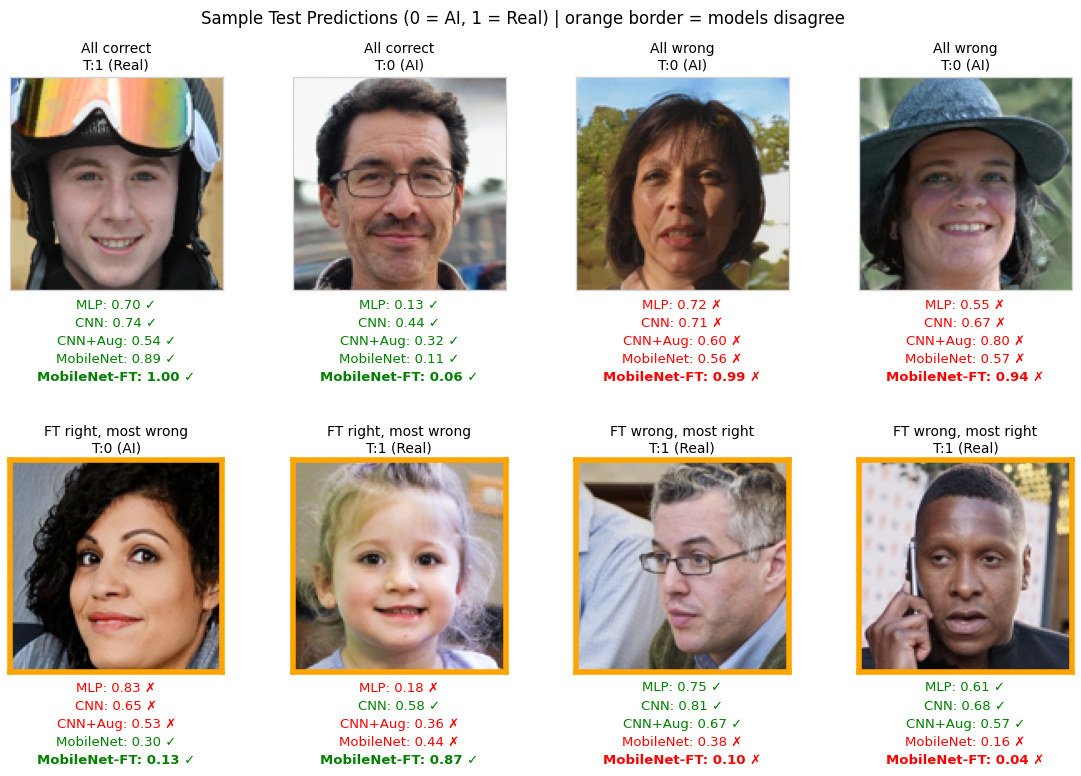

All 5 correct: 81 | All 5 wrong: 12 (Real 3, AI 9) | Disagree: 207  (of 300)
Accuracy on disagreement images: MLP 0.54 | CNN 0.53 | CNN+Aug 0.43 | MobileNet 0.64 | MobileNet-FT 0.71 | Majority 0.64
Avg confidence |p-0.5| on images that fooled all: MLP 0.19 | CNN 0.21 | CNN+Aug 0.16 | MobileNet 0.24 | MobileNet-FT 0.41


In [19]:
#  Pick 8 informative test images: 2 per category
rng = np.random.default_rng(42)
bi = names.index("MobileNet-FT")
categories = {
    "All correct":        np.where(n_correct == 5)[0],
    "All wrong":          np.where(n_correct == 0)[0],
    "FT right, most wrong": np.where(correct[bi] & (n_correct <= 2))[0],
    "FT wrong, most right": np.where(~correct[bi] & (n_correct >= 3))[0],
}
picks, used = [], set()
for cat, idxs in categories.items():
    for i in rng.choice(idxs, size=min(2, len(idxs)), replace=False):
        picks.append((int(i), cat)); used.add(int(i))
while len(picks) < 8:                               # top up if a category was empty
    i = int(rng.integers(len(y_test)))
    if i not in used: picks.append((i, "Random")); used.add(i)

fig, axes = plt.subplots(2, 4, figsize=(14, 8.5))
for ax, (i, cat) in zip(axes.ravel(), picks):
    t = y_test[i]
    ax.imshow(X_test[i]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{cat}\nT:{t} ({'Real' if t else 'AI'})", fontsize=10)
    disagree = 0 < n_correct[i] < len(names)
    for sp in ax.spines.values():                   # orange border = models disagree
        sp.set_edgecolor("orange" if disagree else "lightgray"); sp.set_linewidth(4 if disagree else 1)
    for j, n in enumerate(names):
        ok = correct[j, i]
        ax.text(0.5, -0.04 - 0.085 * j, f"{n}: {P[j, i]:.2f} {'✓' if ok else '✗'}",
                transform=ax.transAxes, ha="center", va="top", fontsize=9.5,
                color="green" if ok else "red", fontweight="bold" if n == "MobileNet-FT" else "normal")
plt.suptitle("Sample Test Predictions (0 = AI, 1 = Real) | orange border = models disagree", fontsize=12)
plt.subplots_adjust(hspace=0.8, top=0.9, bottom=0.2)
plt.savefig("fig_p7_samples.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- Consensus & failure analysis (becomes text in the report) ----
dis    = np.where((n_correct > 0) & (n_correct < 5))[0]
fooled = np.where(n_correct == 0)[0]
print(f"All 5 correct: {np.sum(n_correct == 5)} | All 5 wrong: {len(fooled)} "
      f"(Real {np.sum(y_test[fooled] == 1)}, AI {np.sum(y_test[fooled] == 0)}) | Disagree: {len(dis)}  (of 300)")
print("Accuracy on disagreement images: " +
      " | ".join(f"{n} {np.mean(correct[j, dis]):.2f}" for j, n in enumerate(names)) +
      f" | Majority {np.mean(majority[dis] == y_test[dis]):.2f}")
if len(fooled):
    print("Avg confidence |p-0.5| on images that fooled all: " +
          " | ".join(f"{n} {np.abs(P[j, fooled] - 0.5).mean():.2f}" for j, n in enumerate(names)))

### 📌 Results: model comparison

| Model | Params | Train acc | Val acc | Test acc | AI faces caught | % predicted Real |
|---|---|---|---|---|---|---|
| MLP | 6.3M | 0.868 | 0.667 | 0.643 | 73% | 42% |
| CNN | 31k | 0.661 | 0.633 | 0.633 | 38% | 75% |
| CNN + Aug | 31k | 0.647 | 0.650 | 0.563 | 39% | 68% |
| MobileNet (frozen) | 1.0M | 0.930 | 0.756 | 0.713 | 73% | 49% |
| **MobileNet (fine-tuned)** | 1.0M | 0.996 | 0.806 | **0.760** | **75%** | **51%** |
| Majority vote of all 5 | – | – | – | 0.710 | 64% | 57% |

- **Best model:** the fine-tuned MobileNet, followed by the frozen one. Pretrained features made the biggest difference.
- **Generalization:** the CNNs have the smallest train–validation gap, but only because they barely learned the training data. A small gap is not automatically good.
- **Mistake patterns:** the CNNs call most faces "Real" and miss most AI faces, the worst habit for a fake detector. Both MobileNets are balanced.
- **Faces that fooled every model:** only 12 test images fooled all five models, and most were very realistic AI faces with natural backgrounds. The fine-tuned model was confidently wrong on them, while the others were unsure.
- **When models disagree:** the fine-tuned MobileNet is usually right. A majority vote does worse than it, because the weaker CNNs make the same mistakes and outvote it.

**Takeaway:** the fine-tuned MobileNet is the most accurate and the most balanced, but very realistic fakes can still fool it with high confidence.

## 🎮 Part 8: Interactive Game, Human vs. Model

A 10-round Gradio game: the player and the model classify the same test face, scores and accuracies update live, the correct answer and the model's confidence appear after each guess, and a winner is announced at the end.

- The best model (fine-tuned MobileNetV3) is saved as `best_model.keras`
- Test images are exported as **lossless PNGs**, so the app sees exactly the same pixels as the notebook (verified by reproducing the notebook's test accuracy)
- `app.py` uses `gr.Blocks` with session state and button enable/disable logic, so each round is scored exactly once
- Runs locally with `python app.py` (http://localhost:7860); a demo video is included in the repository

Inspired by [Which Face is Real?](https://whichfaceisreal.com/)

In [20]:
# ============================================================
# Part 8 - Prepare deployment files
# ============================================================
!pip install -q "gradio>=5,<6"

import os, shutil
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image

APP_DIR = "/content/face_game"
os.makedirs(f"{APP_DIR}/test_images", exist_ok=True)

# 1. Best model (fine-tuned MobileNetV3) -> best_model.keras
shutil.copy("best_mobilenet_finetuned.keras", f"{APP_DIR}/best_model.keras")

# 2. Export the fixed test set as lossless PNGs (label encoded in filename)
for i, (img, lab) in enumerate(zip(X_test, y_test)):
    fname = f"{'real' if lab == 1 else 'ai'}_{i:03d}.png"
    Image.fromarray((img * 255).round().astype(np.uint8)).save(f"{APP_DIR}/test_images/{fname}")
print(f"Exported {len(os.listdir(f'{APP_DIR}/test_images'))} test images")

# 3. load images
files = sorted(os.listdir(f"{APP_DIR}/test_images"))
batch = np.stack([np.array(Image.open(f"{APP_DIR}/test_images/{f}").convert("RGB")) for f in files]).astype("float32")
labs  = np.array([1 if f.startswith("real") else 0 for f in files])
m = tf.keras.models.load_model(f"{APP_DIR}/best_model.keras")
app_acc = np.mean((m.predict(batch, verbose=0).ravel() > 0.5) == labs)
print(f"Accuracy with app-style loading: {app_acc:.4f}  (notebook: {mob_ft_test_acc:.4f})")

# 4. requirements.txt
with open(f"{APP_DIR}/requirements.txt", "w") as f:
    f.write(f"tensorflow=={tf.__version__}\ngradio=={gr.__version__}\nnumpy\nPillow\n")

# 5. README.md
with open(f"{APP_DIR}/README.md", "w") as f:
    f.write("# Real or AI? Human vs. Model\n\n"
            "A 10-round game: guess whether each face is real or AI-generated, then see how a "
            "fine-tuned MobileNetV3Small (75% test accuracy) did on the same image.\n\n"
            "Run locally:\n```\npip install -r requirements.txt\npython app.py\n```\n"
            "Then open http://localhost:7860\n")
print(open(f"{APP_DIR}/requirements.txt").read())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.6/325.6 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 462.4/462.4 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 6.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
python-fasthtml 0.14.13 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have

In [21]:
%%writefile /content/face_game/app.py
import os
import random
import numpy as np
import gradio as gr
import tensorflow as tf
from PIL import Image

# configurations
N_ROUNDS = 10
IMG_DIR = "test_images"
MODEL_PATH = "best_model.keras"

# Load model + images once at startup
model = tf.keras.models.load_model(MODEL_PATH)

files  = sorted(f for f in os.listdir(IMG_DIR) if f.endswith(".png"))
images = [np.array(Image.open(os.path.join(IMG_DIR, f)).convert("RGB")) for f in files]
labels = [1 if f.startswith("real") else 0 for f in files]          # 1 = Real, 0 = AI

# MobileNetV3 expects raw [0,255] pixels; sigmoid output = P(Real)
scores = model.predict(np.stack(images).astype("float32"), verbose=0).ravel()

def label_name(y):
    return "Real 👤" if y == 1 else "AI-generated 🤖"

# ---------------- UI helpers ----------------
def banner(text, color):
    return (f"<div style='padding:8px 10px;border-radius:10px;background:{color};"
            f"color:#111 !important;font-size:14px;text-align:center;margin-bottom:6px'>"
            f"<span style='color:#111 !important'>{text}</span></div>")

def round_text(s):
    current = s["round"] if s["answered"] else s["round"] + 1
    return f"### Round {current} / {N_ROUNDS}"


def score_html(s):
    done = s["round"]
    def box(title, pts, color):
        acc = f"{100 * pts / done:.0f}%" if done else "–"
        dark = "color:#111 !important"
        return (f"<div style='flex:1;padding:8px;border-radius:10px;background:{color};text-align:center;{dark}'>"
                f"<div style='font-size:13px;{dark}'>{title}</div>"
                f"<div style='font-size:22px;font-weight:700;{dark}'>{pts} / {done}</div>"
                f"<div style='font-size:12px;{dark}'>accuracy {acc}</div></div>")
    return ("<div style='display:flex;gap:8px;margin-bottom:6px'>"
            + box("🧑 You", s["human"], "#dbeafe") + box("🤖 Model", s["model"], "#fde68a") + "</div>")

# ---------------- Game logic ----------------
# Every handler returns: state, image, round, score, feedback, btn_real, btn_ai, btn_next
def show_round(s):
    s["answered"] = False
    idx = s["order"][s["round"]]
    return (s, images[idx], round_text(s), score_html(s),
            banner("Is this face <b>Real</b> or <b>AI-generated</b>?", "#f3f4f6"),
            gr.update(interactive=True), gr.update(interactive=True), gr.update(interactive=False))

def new_game():
    s = {"order": random.sample(range(len(files)), N_ROUNDS),
         "round": 0, "human": 0, "model": 0, "answered": False}
    return show_round(s)

def guess(choice, s):
    if s is None or s["answered"]:                       # ignore double clicks
        return (s,) + tuple(gr.update() for _ in range(7))

    idx = s["order"][s["round"]]
    truth, p = labels[idx], float(scores[idx])
    model_guess = int(p > 0.5)
    conf = p if model_guess == 1 else 1 - p
    human_ok, model_ok = (choice == truth), (model_guess == truth)

    s["human"] += int(human_ok)
    s["model"] += int(model_ok)
    s["round"] += 1
    s["answered"] = True

    fb = banner(f"Answer: <b>{label_name(truth)}</b><br>"
                f"You said {label_name(choice)} {'✅' if human_ok else '❌'} &nbsp;|&nbsp; "
                f"Model said {label_name(model_guess)} ({conf:.0%} sure) {'✅' if model_ok else '❌'}",
                "#bbf7d0" if human_ok else "#fecaca")

    finished = s["round"] >= N_ROUNDS
    if finished:
        if s["human"] > s["model"]:
            result = "🎉🎉 You beat the AI detector! 🎉🎉"
        elif s["human"] < s["model"]:
            result = "🤖 The model wins this time. Rematch?"
        else:
            result = "🤝 It's a tie!"
        fb += banner(f"<b>Game over!</b> You {s['human']}/{N_ROUNDS} vs Model {s['model']}/{N_ROUNDS}"
                     f"<br><span style='font-size:22px'>{result}</span><br>"
                     f"Press <b>New Game</b> to play again.", "#e9d5ff")

    return (s, gr.update(), round_text(s), score_html(s), fb,
            gr.update(interactive=False), gr.update(interactive=False),
            gr.update(interactive=not finished))

def next_round(s):
    if s is None or not s["answered"] or s["round"] >= N_ROUNDS:
        return (s,) + tuple(gr.update() for _ in range(7))
    return show_round(s)

# ---------------- Layout ----------------
CSS = """
.gradio-container {max-width: 820px !important; margin: 0 auto !important;}
"""

with gr.Blocks(theme=gr.themes.Soft(), css=CSS, title="Real or AI? Human vs. Model") as demo:
    gr.Markdown("## 🤖 Real or AI? Human vs. Model\n"
                f"Is the face **real** or **AI-generated**? A fine-tuned MobileNetV3 answers the "
                f"same image. Best of {N_ROUNDS} rounds wins!")
    state = gr.State()
    with gr.Row(equal_height=False):
        # Left: image + guess buttons
        with gr.Column(scale=1, min_width=260):
            img = gr.Image(show_label=False, height=260, interactive=False)
            with gr.Row():
                btn_real = gr.Button("👤 Real", variant="primary", interactive=False)
                btn_ai   = gr.Button("🤖 AI-Generated", variant="primary", interactive=False)
        # Right: round, scores, feedback, navigation
        with gr.Column(scale=1, min_width=260):
            round_md = gr.Markdown()
            score    = gr.HTML()
            feedback = gr.HTML()
            with gr.Row():
                btn_next = gr.Button("➡️ Next Image", size="sm", interactive=False)
                btn_new  = gr.Button("🔄 New Game", size="sm", variant="secondary")

    outputs = [state, img, round_md, score, feedback, btn_real, btn_ai, btn_next]
    btn_new.click(new_game, None, outputs)
    btn_real.click(lambda s: guess(1, s), state, outputs)
    btn_ai.click(lambda s: guess(0, s), state, outputs)
    btn_next.click(next_round, state, outputs)
    demo.load(new_game, None, outputs)

if __name__ == "__main__":
    demo.launch()

Writing /content/face_game/app.py


In [22]:
%cd /content/face_game
%run app.py
%cd /content

/content/face_game


/content/face_game/app.py:109: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), css=CSS, title="Real or AI? Human vs. Model") as demo:
/content/face_game/app.py:109: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), css=CSS, title="Real or AI? Human vs. Model") as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://59e7a5bbf264e42fee.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/content


<Figure size 640x480 with 0 Axes>

In [23]:
import shutil
from google.colab import files
shutil.make_archive("/content/face_game", "zip", "/content/face_game")
files.download("/content/face_game.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reflections
The biggest lesson was that small training choices (how the best model is selected, the learning rate, and BatchNorm handling) mattered as much as the architecture itself. Transfer learning gave the largest improvement. With only 180 validation images, results varied from run to run, so repeating key experiments over several random seeds would make the comparisons more reliable.

**Next steps:** higher input resolution (128×128 may discard high-frequency generation artifacts) and frequency-domain features, since AI-generated images often leave traces in Fourier space.